In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split


pd.set_option("display.max_columns", 100)
pd.set_option("display.width", 200)

sns.set(style="whitegrid")

In [2]:
DATA_PATH = "../logs.parquet"

df_all = pd.read_parquet(DATA_PATH)
print("Raw data shape:", df_all.shape)

games = df_all["session_id"].unique()

train_ids, test_ids = train_test_split(
    games,
    test_size=0.30,
    random_state=42,
    shuffle=True
)

train_df = df_all[df_all["session_id"].isin(train_ids)].copy()
test_df  = df_all[df_all["session_id"].isin(test_ids)].copy()

print("Train shape:", train_df.shape)
print("Test shape: ", test_df.shape)


df = train_df.copy()

Raw data shape: (13352, 26)
Train shape: (9378, 26)
Test shape:  (3974, 26)


 ## 1. Data overview

In [3]:
print("\nColumns:")
print(df.columns.tolist())

print("\nDtypes:")
print(df.dtypes)

print("\nFirst rows (train):")
display(df.head())


Columns:
['id', 'session_id', 'player_mark', 'board', 'legal_moves', 'ai_move', 'game_status', 'timestamp', 'mcts_iterations', 'exploration_constant', 'visit_counts_json', 'action_scores_json', 'policy_vector_json', 'best_visit_count', 'best_q_value', 'move_confidence', 'branching_factor', 'explored_actions', 'mcts_tree_size', 'rollout_count', 'rollout_depth_avg', 'rollout_depth_max', 'mcts_search_duration_ms', 'ai_latency_ms', 'ai_difficulty', 'final_result']

Dtypes:
id                                 object
session_id                         object
player_mark                        object
board                              object
legal_moves                        object
ai_move                            object
game_status                        object
timestamp                  datetime64[ns]
mcts_iterations                     int64
exploration_constant               object
visit_counts_json                  object
action_scores_json                 object
policy_vector_json   

,id,session_id,player_mark,board,legal_moves,ai_move,game_status,timestamp,mcts_iterations,exploration_constant,visit_counts_json,action_scores_json,policy_vector_json,best_visit_count,best_q_value,move_confidence,branching_factor,explored_actions,mcts_tree_size,rollout_count,rollout_depth_avg,rollout_depth_max,mcts_search_duration_ms,ai_latency_ms,ai_difficulty,final_result
0,05656954-e111-410d-8c55-28518a705827,994f7a62-03cc-496b-ad64-e9b39c738dad,X,"[["""", """", """"], ["""", """", """"], ["""", """", """"]]","[{""row"": 0, ""col"": 0}, {""row"": 0, ""col"": 1}, {...","{""row"": 0, ""col"": 0}",IN_PROGRESS,2025-12-16 11:27:58.503059,8,0.7071067811865475,"{'0,0': 1, '0,1': 1, '0,2': 1, '1,0': 1, '1,1'...","{'0,0': 1.0, '0,1': 1.0, '0,2': 1.0, '1,0': -1...","{'0,0': 0.125, '0,1': 0.125, '0,2': 0.125, '1,...",1,1.0,0.125,9,8,9,8,0,0,7,7,MEDIUM,None
1,2d179bc3-f339-4ee0-b1f2-180844d9252f,994f7a62-03cc-496b-ad64-e9b39c738dad,O,"[[""X"", """", """"], ["""", """", """"], ["""", """", """"]]","[{""row"": 0, ""col"": 1}, {""row"": 0, ""col"": 2}, {...","{""row"": 0, ""col"": 1}",IN_PROGRESS,2025-12-16 11:27:58.525978,8,0.7071067811865475,"{'0,1': 1, '0,2': 1, '1,0': 1, '1,1': 1, '1,2'...","{'0,1': -1.0, '0,2': -1.0, '1,0': -1.0, '1,1':...","{'0,1': 0.125, '0,2': 0.125, '1,0': 0.125, '1,...",1,1.0,0.125,8,8,9,8,0,0,5,5,MEDIUM,None
2,73672acd-95b3-4f10-a24b-af2eb7f8345e,994f7a62-03cc-496b-ad64-e9b39c738dad,X,"[[""X"", ""O"", """"], ["""", """", """"], ["""", """", """"]]","[{""row"": 0, ""col"": 2}, {""row"": 1, ""col"": 0}, {...","{""row"": 1, ""col"": 0}",IN_PROGRESS,2025-12-16 11:27:58.538718,8,0.7071067811865475,"{'0,2': 1, '1,0': 2, '1,1': 1, '1,2': 1, '2,0'...","{'0,2': 0.0, '1,0': 1.0, '1,1': 1.0, '1,2': -1...","{'0,2': 0.125, '1,0': 0.25, '1,1': 0.125, '1,2...",2,1.0,0.25,7,7,9,8,0,0,3,3,MEDIUM,None
3,22d5e45f-5bbc-4e06-b00b-50ce9af72b24,994f7a62-03cc-496b-ad64-e9b39c738dad,O,"[[""X"", ""O"", """"], [""X"", """", """"], ["""", """", """"]]","[{""row"": 0, ""col"": 2}, {""row"": 1, ""col"": 1}, {...","{""row"": 0, ""col"": 2}",IN_PROGRESS,2025-12-16 11:27:58.548836,8,0.7071067811865475,"{'0,2': 2, '1,1': 2, '1,2': 1, '2,0': 1, '2,1'...","{'0,2': -1.0, '1,1': 0.0, '1,2': -1.0, '2,0': ...","{'0,2': 0.25, '1,1': 0.25, '1,2': 0.125, '2,0'...",2,0.0,0.25,6,6,9,8,0,0,1,1,MEDIUM,None
4,d87d194a-8f92-4660-bb50-a12ca166a778,994f7a62-03cc-496b-ad64-e9b39c738dad,X,"[[""X"", ""O"", ""O""], [""X"", """", """"], ["""", """", """"]]","[{""row"": 1, ""col"": 1}, {""row"": 1, ""col"": 2}, {...","{""row"": 1, ""col"": 1}",IN_PROGRESS,2025-12-16 11:27:58.557814,8,0.7071067811865475,"{'1,1': 2, '1,2': 2, '2,0': 2, '2,1': 1, '2,2'...","{'1,1': 1.0, '1,2': 1.0, '2,0': 1.0, '2,1': 1....","{'1,1': 0.25, '1,2': 0.25, '2,0': 0.25, '2,1':...",2,1.0,0.25,5,5,8,8,0,0,1,1,MEDIUM,None


In [4]:
missing = df.isna().sum().sort_values(ascending=False)
print("Missing values in train set:")
display(missing[missing > 0])

Missing values in train set:


final_result    8048
dtype: int64

## 2. Game Structure
Here we analyze:
how many unique games we have,how many moves per game,distribution of game lengths.
This shows dataset diversity and helps detect abnormal or corrupted gameplay logs.

Unique games: 1330

Move count statistics per game:
count    1330.000000
mean        7.051128
std         1.274430
min         5.000000
25%         6.000000
50%         7.000000
75%         8.000000
max         9.000000
dtype: float64


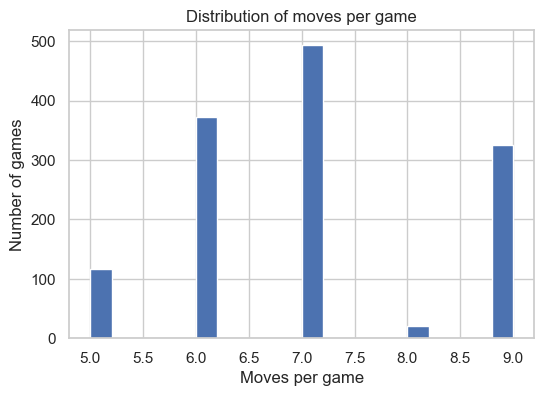

In [5]:
n_games = df["session_id"].nunique()
print(f"Unique games: {n_games}")

# Count moves per game
if "logged_at" in df.columns:
    moves_per_game = df.groupby("session_id")["logged_at"].count()
else:
    moves_per_game = df.groupby("session_id").size()

print("\nMove count statistics per game:")
print(moves_per_game.describe())

plt.figure(figsize=(6,4))
moves_per_game.hist(bins=20)
plt.xlabel("Moves per game")
plt.ylabel("Number of games")
plt.title("Distribution of moves per game")
plt.show()

## 3. Final Outcome
We compute the final outcome of each game and analyze:
outcome distribution,potential imbalance (e.g., many wins vs few draws).
This is important to understand the target variable distribution later.


Final outcome distribution:


final_result
WIN     1004
DRAW     326
Name: count, dtype: int64

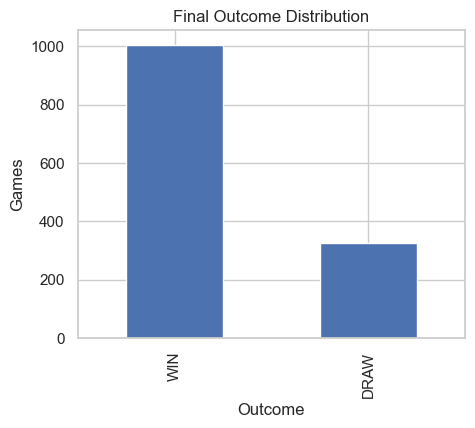

In [6]:
sort_cols = ["session_id", "timestamp"]
final_outcome_per_game = (
    df.sort_values(sort_cols)
      .groupby("session_id")["final_result"]
      .last()
)

print("\nFinal outcome distribution:")
display(final_outcome_per_game.value_counts())

plt.figure(figsize=(5, 4))
final_outcome_per_game.value_counts().plot(kind="bar")
plt.title("Final Outcome Distribution")
plt.xlabel("Outcome")
plt.ylabel("Games")
plt.show()

 ## 4. Board State Coverage
We explore how many unique board states appear in the dataset and how often they repeat.This helps us understand:
the size of the state space,whether states are highly unique (harder to generalize),or repetitive (easier for ML).
This insight is essential for training a generalizable win-probability model.

Total rows: 9378
Unique board states: 437
Uniqueness ratio: 4.66%


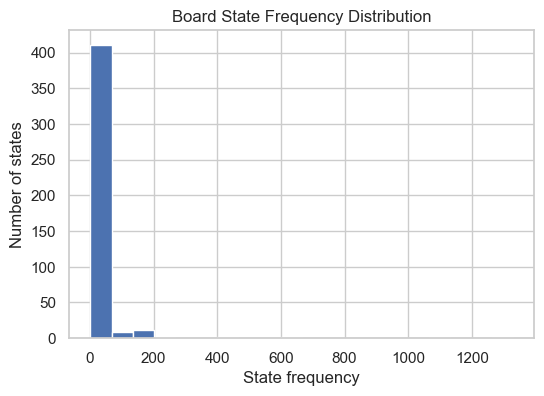

In [7]:
df["board_str"] = df["board"].astype(str)
state_counts = df["board"].value_counts(dropna=False)
unique_states = state_counts.shape[0]

print(f"Total rows: {len(df)}")
print(f"Unique board states: {unique_states}")
print(f"Uniqueness ratio: {unique_states / len(df):.2%}")

plt.figure(figsize=(6, 4))
state_counts.hist(bins=20)
plt.xlabel("State frequency")
plt.ylabel("Number of states")
plt.title("Board State Frequency Distribution")
plt.show()

 ## 5. Game Phase Analysis (Move index)

count    9378.000000
mean        4.140648
std         2.212249
min         1.000000
25%         2.000000
50%         4.000000
75%         6.000000
max         9.000000
Name: move_index, dtype: float64


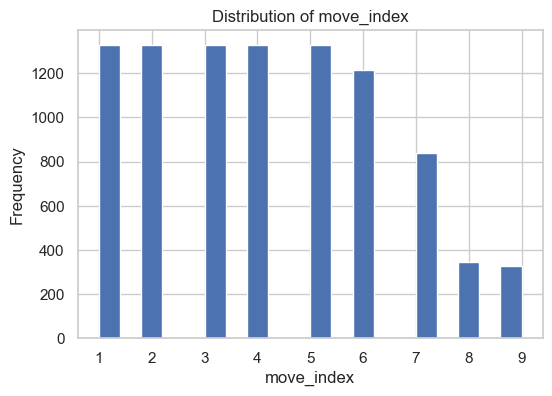

In [8]:
df = df.sort_values(["session_id", "timestamp"])
df["move_index"] = df.groupby("session_id").cumcount() + 1

print(df["move_index"].describe())

plt.figure(figsize=(6, 4))
df["move_index"].hist(bins=20)
plt.xlabel("move_index")
plt.ylabel("Frequency")
plt.title("Distribution of move_index")
plt.show()


## 6. Player to Move
We inspect the distribution of the player on move.This confirms whether:
both players are represented fairly,logging is consistent,no corrupted entries exist.

player_mark
X    5157
O    4221
Name: count, dtype: int64


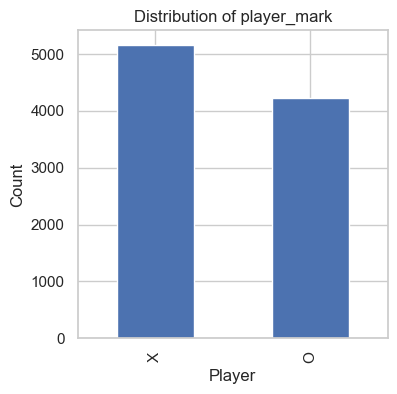

In [9]:
print(df["player_mark"].value_counts())

plt.figure(figsize=(4, 4))
df["player_mark"].value_counts().plot(kind="bar")
plt.title("Distribution of player_mark")
plt.xlabel("Player")
plt.ylabel("Count")
plt.show()

## 8. Target exploration
In this section we explore how a potential target win_label_pov would look like.
We only compute it temporarily on the training set to inspect its distribution.
The final target will be created later in a dedicated data-cleaning / target-engineering step.

In [10]:
print("Final result values:")
print(df["final_result"].value_counts())

tmp = df[["session_id", "player_mark", "final_result", "move_index"]].copy()
tmp = tmp.sort_values(["session_id", "move_index"])

# determine winner per game
last_row = tmp.groupby("session_id").tail(1)
winner_by_game = last_row[last_row["final_result"] == "WIN"] \
                    .set_index("session_id")["player_mark"]

tmp["winner_player"] = tmp["session_id"].map(winner_by_game)

def win_pov(row):
    if row["final_result"] == "DRAW":
        return 0.5
    if row["final_result"] not in ("WIN", "LOSS"):
        return np.nan
    if pd.isna(row["winner_player"]):
        return np.nan
    return 1.0 if row["player_mark"] == row["winner_player"] else 0.0

tmp["win_label_pov"] = tmp.apply(win_pov, axis=1)
print("\nTemporary win_label_pov distribution:")
display(tmp["win_label_pov"].value_counts(dropna=False))
print("\nUsable states ratio:", f"{tmp['win_label_pov'].notna().mean():.2%}")

Final result values:
final_result
WIN     1004
DRAW     326
Name: count, dtype: int64

Temporary win_label_pov distribution:


win_label_pov
NaN    8048
1.0    1004
0.5     326
Name: count, dtype: int64


Usable states ratio: 14.18%


## 10. Outliers

Number of potential outlier games: 0


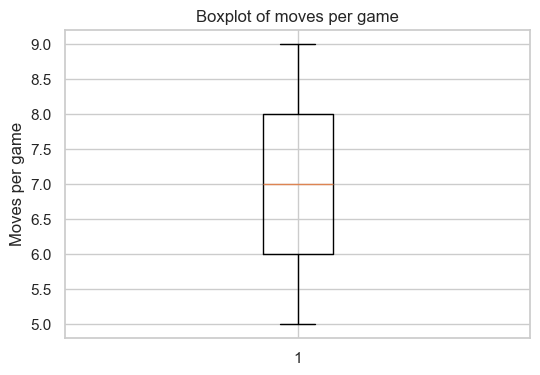

In [11]:
mpg = df.groupby("session_id").size()
Q1, Q3 = mpg.quantile(0.25), mpg.quantile(0.75)
IQR = Q3 - Q1
lower, upper = Q1 - 1.5 * IQR, Q3 + 1.5 * IQR
outliers = mpg[(mpg < lower) | (mpg > upper)]

print(f"Number of potential outlier games: {len(outliers)}")

plt.figure(figsize=(6, 4))
plt.boxplot(mpg, vert=True)
plt.ylabel("Moves per game")
plt.title("Boxplot of moves per game")
plt.show()

Q1 = 2.00, Q3 = 6.00, IQR = 4.00
Lower bound = -4.00, Upper bound = 12.00
Number of potential outlier states (move_index): 0


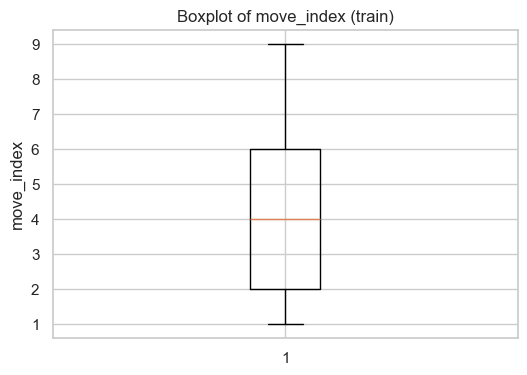

In [12]:
mi = df["move_index"].copy()

Q1 = mi.quantile(0.25)
Q3 = mi.quantile(0.75)
IQR = Q3 - Q1

lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

outliers_mask = (mi < lower_bound) | (mi > upper_bound)
n_outliers = outliers_mask.sum()

print(f"Q1 = {Q1:.2f}, Q3 = {Q3:.2f}, IQR = {IQR:.2f}")
print(f"Lower bound = {lower_bound:.2f}, Upper bound = {upper_bound:.2f}")
print(f"Number of potential outlier states (move_index): {n_outliers}")

plt.figure(figsize=(6,4))
plt.boxplot(mi, vert=True)
plt.ylabel("move_index")
plt.title("Boxplot of move_index (train)")
plt.show()

## 11. Correlation matrix

Numeric columns used for correlation matrix:
['move_index', 'win_label_pov']


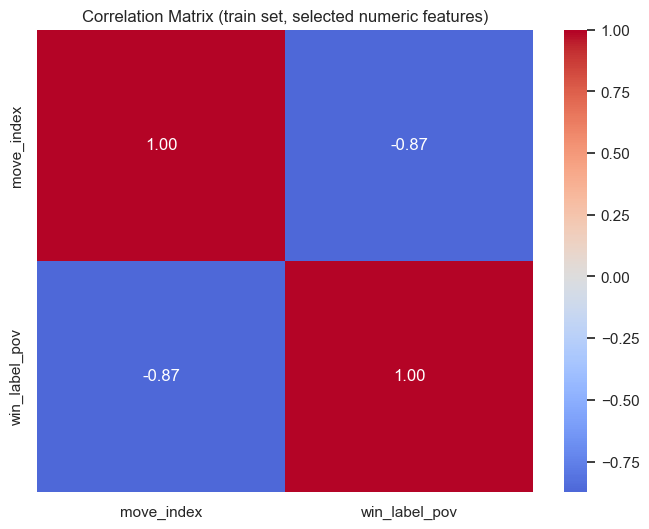

In [13]:
tmp_with_label = tmp.copy()
tmp_with_label["win_label_pov_tmp"] = win_pov

# Select numeric columns only
numeric_df = tmp_with_label.select_dtypes(include=[np.number]).copy()

# Optionally drop columns that are constant or all-NaN
numeric_df = numeric_df.loc[:, numeric_df.nunique(dropna=True) > 1]

print("Numeric columns used for correlation matrix:")
print(numeric_df.columns.tolist())

corr = numeric_df.corr()

plt.figure(figsize=(8, 6))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", center=0)
plt.title("Correlation Matrix (train set, selected numeric features)")
plt.show()